# Pick 10 stocks each industry, from 10 industries. From that 100 stocks, pick 10 with the highest growth in the last month, buy and hold it for the next month. Rebalancing monthly, 10% each stock.


In [1]:
!pip install yfinance

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
from scipy.stats import gmean
import yfinance as yf
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from datetime import datetime, timedelta, date, time
warnings.filterwarnings('ignore')

In [7]:
tickers = ['SPY',"NVDA", "MSFT", "AAPL", "AMZN", "GOOGL", "META", "AVGO", "BRK-B", "TSLA", "JPM",
    "WMT", "LLY", "V", "ORCL", "NFLX", "MA", "XOM", "COST", "PG", "JNJ",
    "HD", "BAC", "ABBV", "PLTR", "KO", "UNH", "PM", "TMUS", "CSCO", "WFC",
    "CRM", "GE", "AMD", "DOW", "NKE", "MCD", "PFE", "TXN", "MRK", "IBM",
    "ADBE", "INTC", "T", "UPS", "AMGN", "QCOM", "VZ", "SO", "BMY", "HON",
    "LIN", "CVX", "CAT", "GS", "NEE", "LOW", "SPGI", "MS", "BLK", "RTX",
    "NOW", "SCHW", "BA", "ISRG", "CI", "MDT", "DE", "ELV", "AXP", "INTU",
    "ADP", "CB", "TJX", "PYPL", "C", "ZTS", "PGR", "DUK", "MMC", "LMT",
    "VRTX", "SYK", "TMO", "BDX", "MO", "ADI", "REGN", "BKNG", "ICE", "ABNB",
    "FDX", "GM", "NSC", "FIS", "HUM", "CL", "GILD", "WM", "EW", "AON",
    "ROST", "DHR", "PNC", "ETN", "ITW", "SHW", "CSX", "MNST", "TRV", "EMR",
    "AEP", "ALL", "GD", "PSX", "HCA", "MCO", "MAR", "APD", "EOG", "LRCX",
    "KLAC", "PCAR", "CDNS", "MCK", "CTAS", "ORLY", "AFL", "STZ", "ANET", "FTNT",
    "KHC", "PAYX", "PH", "MTD", "CTSH", "TGT", "AZO", "IDXX", "TT", "SRE",
    "WELL", "DLR", "F", "CME", "PXD", "ED", "MRNA", "CMI", "NEM", "HSY",
    "WBA", "TEL", "ODFL", "BIIB", "HPQ", "CARR", "AME", "COF", "HES", "D",
    "AIG", "A", "MSI", "EXC", "RSG", "YUM", "HIG", "O", "XEL", "TSCO",
    "CHD", "DFS", "KEYS", "FAST", "EFX", "TDG", "ACN", "BKR", "CEG", "GPN",
    "KMB", "AVB", "VRSK", "FRC", "CDW", "HLT", "CMS", "ROL", "NUE", "ATO",
    "VLO", "ZBH", "QRVO", "IP", "MTB", "FTV", "ULTA", "MLM", "LH", "HOLX",
    "INCY", "WAT", "XYL", "LUV", "PKI", "NVR", "SJM", "PPG", "NDAQ", "DRI"]
# List of companies
data = yf.download(tickers, start='2015-01-01', end='2025-08-01', interval="1mo")['Close'].pct_change()
data.set_index(pd.to_datetime(data.index), inplace=True)
print(data.head())

[*********************100%***********************]  211 of 211 completed
ERROR:yfinance:
4 Failed downloads:
ERROR:yfinance:['PKI', 'PXD', 'DFS']: YFTzMissingError('possibly delisted; no timezone found')
ERROR:yfinance:['FRC']: YFPricesMissingError('possibly delisted; no price data found  (1mo 2015-01-01 -> 2025-08-01)')


Ticker             A      AAPL      ABBV  ABNB       ACN      ADBE       ADI  \
Date                                                                           
2015-01-01       NaN       NaN       NaN   NaN       NaN       NaN       NaN   
2015-02-01  0.120290  0.096449  0.010012   NaN  0.071403  0.127905  0.123393   
2015-03-01 -0.015636 -0.027549 -0.032397   NaN  0.040653 -0.065234  0.083457   
2015-04-01 -0.001880  0.005786  0.104544   NaN -0.011100  0.028672 -0.018413   
2015-05-01 -0.004350  0.040991  0.038390   NaN  0.047676  0.039837  0.098965   

Ticker           ADP       AEP       AFL  ...      WELL       WFC        WM  \
Date                                      ...                                 
2015-01-01       NaN       NaN       NaN  ...       NaN       NaN       NaN   
2015-02-01  0.076457 -0.083267  0.090575  ... -0.059060  0.055278  0.059304   
2015-03-01 -0.036020 -0.014737  0.034800  ...  0.013485 -0.000574 -0.004589   
2015-04-01 -0.007131  0.011022 -0.015154  ..

In [18]:
if 'monthly_pnl' in data.columns:
    data = data.drop('monthly_pnl', axis=1)

current = []
total_pnls = [0,0]
for i in range(2, len(data)):
    last_month = data.index[i-1]
    current_month = data.index[i]

# for month in data.index:
    top_10_monthly = data.loc[last_month].dropna().sort_values(ascending=False).head(10)
    # print(f"Top 10 tickers for {last_month}: {top_10_monthly.index.tolist()}")
    for top_ticker in top_10_monthly.index:
        current.append(data.loc[current_month, top_ticker])
    total_pnls.append(np.mean(current))
    current = []

data['monthly_pnl'] = total_pnls
for pnl in total_pnls:
    print(pnl)
# data['monthly_pnl'] = data['temp_monthly_pnl'].shift(1)
# data = data.drop('temp_monthly_pnl', axis=1)
data = data.fillna(0)
# data

0
0
-0.028457449592002537
-0.043700027212324036
0.02465738873534813
-0.00807952692211128
0.02374701531929958
-0.057787852339940084
-0.005624865123785239
0.052646377915893716
0.022266570563610012
0.0002559341302396101
-0.06376563844078108
0.0434899130743974
0.057175147035550454
0.06631025298975998
0.030854679726071275
-0.008979855705328776
0.04636642076895818
0.009902155659966928
-0.004819692573780477
-0.014829316210465826
0.06183685222758378
0.05437153831476464
0.009548884360613763
0.02663580843007669
0.007286693393990263
0.03348367387108357
0.06634875899479072
-0.03916204191934937
0.01431202937197027
0.00978148750458403
0.015053042882889833
0.02238325214585176
0.033033693987075174
0.018884577174637686
0.059917221360658676
-0.01544692190629916
-0.011923507212805818
0.025995581229854337
0.00036550544343050273
0.0066863560568431344
-0.019315915650767835
0.07453421212409733
0.033623247264190845
-0.133479172218757
0.018455612582985025
-0.09315451518354288
0.0875888843131514
0.0358904426182

In [5]:
sharpe_ratio = np.mean(total_pnls) / np.std(total_pnls)
print(f"Sharpe Ratio: {sharpe_ratio}")

Sharpe Ratio: 0.31008840676225663


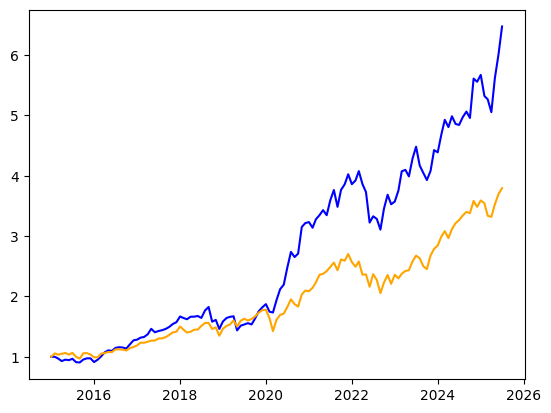

In [6]:
dates = data.index
spy = data['SPY']
# Plot profit
# plt.plot(dates, np.cumsum(total_pnls))
#plt.plot(dates,np.cumprod(1+np.array(total_pnls)),'-o')
plt.plot(dates,np.cumprod(1+np.array(total_pnls)),color = 'blue')
plt.plot(dates,np.cumprod(1+np.array(spy)),color = 'orange')
#plt.plot(dates, np.cumsum(total_pnls))